In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

file_path = Path("../Online Retail.xlsx")

if not file_path.exists():
    file_path = Path("Online Retail.xlsx")

df = pd.read_excel(file_path)

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## سؤال ۱: دیتاست چند رکورد و چند ستون دارد؟

### پاسخ

دیتاست شامل **541,909 ردیف و 8 ستون** است.

هر ردیف نشان‌دهنده یک ردیف کالایی ثبت‌شده در یک فاکتور است؛ بنابراین هر ردیف الزاماً یک سفارش یا یک مشتری مستقل نیست.

### چرا این سؤال را می‌پرسیم؟

شناخت ابعاد دیتاست اولین قدم در Data Understanding است. این بررسی به ما کمک می‌کند حجم داده، تعداد متغیرهای در دسترس و سطح اولیه پیچیدگی تحلیل را بشناسیم.

### تحلیل داده‌کاو

حجم داده برای تحلیل مقدماتی رفتار خرید مشتریان مناسب است؛ اما تعداد زیاد ردیف‌ها به‌تنهایی به معنای کیفیت بالا یا مناسب‌بودن داده برای پیش‌بینی ریزش نیست. باید ساختار، کیفیت و پوشش زمانی آن نیز بررسی شود.

In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)

Number of rows: 541909
Number of columns: 8
Dataset shape: (541909, 8)


## سؤال ۲: واحد هر رکورد چیست و ستون‌ها چه اطلاعاتی ارائه می‌کنند؟

### پاسخ
هر ردیف، یک قلم کالا در یک فاکتور را نشان می‌دهد. دیتاست دارای 8 ستون است:

- `InvoiceNo`: شناسه فاکتور؛ شماره‌هایی که با C شروع می‌شوند نشان‌دهنده لغو فاکتور هستند.
- `StockCode`: شناسه محصول
- `Description`: نام یا شرح محصول
- `Quantity`: تعداد واحدهای کالا در ردیف فاکتور
- `InvoiceDate`: تاریخ و زمان ثبت تراکنش
- `UnitPrice`: قیمت هر واحد کالا به پوند استرلینگ
- `CustomerID`: شناسه مشتری
- `Country`: کشور محل اقامت مشتری

### چرا این سؤال را می‌پرسیم؟

برای فهم معنای واقعی متغیرها و جلوگیری از تحلیل اشتباه. برای مثال، تعداد ردیف‌ها معادل تعداد فاکتورها نیست و `CustomerID` نیز یک شناسه است، نه یک متغیر عددی قابل تفسیر به‌صورت کمّی.

### تحلیل داده‌کاو

اطلاعات اصلی دیتاست مربوط به تراکنش، محصول، قیمت، زمان و شناسه مشتری است. اطلاعاتی مانند سن مشتری، جنسیت، علت نارضایتی یا سابقه تماس با پشتیبانی در این دیتاست وجود ندارد.

In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nSample records:")
print(df.head())

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types:
InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID     float64
Country            str
dtype: object

Sample records:
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

    InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/10 8:26       2.55     17850.0  United Kingdom  
1  12/1/10 8:26       3.39     17850.0  United Kingdom  
2  12/1/10 8:26       2.75     17850.0  United 

## سؤال ۳: تعداد موجودیت‌های یکتا در دیتاست چقدر است؟

### پاسخ
بررسی فایل نشان می‌دهد:

- تعداد فاکتورهای یکتا: 25,900
- تعداد مشتریان دارای شناسه یکتا: 4,372
- تعداد کدهای محصول یکتا: 4,070
- تعداد کشورهای یکتا: 38

### چرا این سؤال را می‌پرسیم؟

چون در پروژه پیش‌بینی ریزش، واحد اصلی تحلیل مشتری است؛ نه ردیف فاکتور. شناخت تعداد مشتریان و فاکتورها مشخص می‌کند با چه حجمی از رفتار مشتریان روبه‌رو هستیم.

### تحلیل داده‌کاو

541,909 ردیف داده به معنی 541,909 مشتری نیست. هر مشتری ممکن است در چند فاکتور و هر فاکتور در چندین ردیف کالایی حضور داشته باشد.

همچنین تعداد مشتریان یکتا فقط مشتریانی را شامل می‌شود که شناسه قابل شناسایی دارند.

In [ ]:
print("Unique invoices:", df["InvoiceNo"].nunique())
print("Unique customers:", df["CustomerID"].nunique())
print("Unique products:", df["StockCode"].nunique())
print("Unique countries:", df["Country"].nunique())

Unique invoices: 25900
Unique customers: 4372
Unique products: 4070
Unique countries: 38


## سؤال ۴: تعداد و درصد داده‌های گمشده در هر ستون چقدر است؟

### پاسخ
بررسی دیتاست نشان می‌دهد:

- ستون `CustomerID` دارای 135,080 مقدار گمشده است؛ حدود 24.93 درصد کل ردیف‌ها.
- ستون `Description` دارای 1,454 مقدار گمشده است؛ حدود 0.27 درصد کل ردیف‌ها.
- شش ستون دیگر مقدار گمشده ندارند.

### چرا این سؤال را می‌پرسیم؟

داده‌های گمشده می‌توانند قابلیت تحلیل و استفاده از رکوردها را محدود کنند. در پروژه ریزش مشتری، وجود `CustomerID` اهمیت ویژه‌ای دارد؛ زیرا بدون آن نمی‌توان سابقه خرید یک رکورد را به مشتری مشخصی نسبت داد.

### تحلیل داده‌کاو

گم‌شدن شناسه مشتری، مهم‌ترین مسئله مربوط به کامل‌بودن داده در این دیتاست است. حدود یک‌چهارم ردیف‌ها فاقد شناسه مشتری‌اند و نمی‌توان آن‌ها را مستقیماً به مشتری مشخصی نسبت داد.

در این مرحله فقط مقادیر گمشده را شناسایی می‌کنیم و هیچ مقداری را حذف یا جایگزین نمی‌کنیم.

             Missing_Count  Missing_Percent
CustomerID          135080        24.926694
Description           1454         0.268311
StockCode                0         0.000000
InvoiceNo                0         0.000000
Quantity                 0         0.000000
InvoiceDate              0         0.000000
UnitPrice                0         0.000000
Country                  0         0.000000


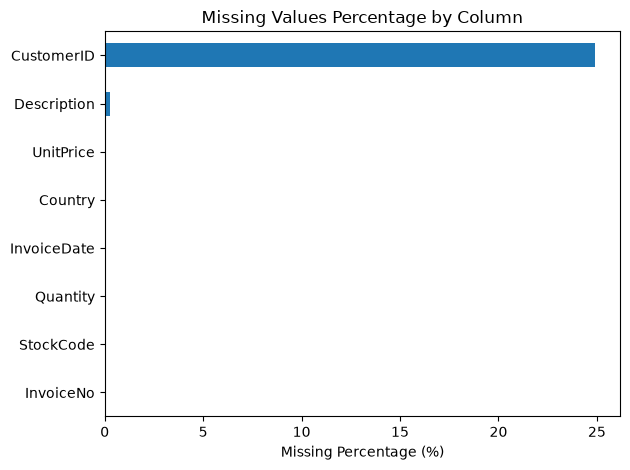

In [ ]:
missing_count = df.isna().sum()
missing_percent = df.isna().mean() * 100

missing_report = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percent": missing_percent
})

print(missing_report.sort_values(
    by="Missing_Percent",
    ascending=False
))

missing_report["Missing_Percent"].sort_values().plot(
    kind="barh",
    title="Missing Values Percentage by Column",
    xlabel="Missing Percentage (%)"
)

plt.tight_layout()
plt.show()

## سؤال ۵: چند ردیف کاملاً تکراری در دیتاست وجود دارد؟

### پاسخ
در فایل، **5,268 ردیف تکراری کامل** شناسایی شده است؛ یعنی حدود 0.97 درصد کل ردیف‌ها.

### چرا این سؤال را می‌پرسیم؟

وجود ردیف‌های کاملاً یکسان ممکن است باعث شمارش مجدد یک ثبت تراکنش و اثرگذاری بر آمار خرید، تعداد کالاها یا تحلیل رفتار مشتری شود.

### تحلیل داده‌کاو

وجود ردیف‌های تکراری لزوماً ثابت نمی‌کند که تمام آن‌ها خطا هستند. در این مرحله باید تعداد و نمونه‌های آن‌ها را ثبت کنیم و در مرحله Data Preparation درباره نحوه برخورد با آن‌ها تصمیم بگیریم.

هیچ ردیفی در این بررسی حذف نمی‌شود.

In [ ]:
duplicate_count = df.duplicated().sum()
duplicate_percent = df.duplicated().mean() * 100

print("Duplicate rows:", duplicate_count)
print("Duplicate percentage:", round(duplicate_percent, 2), "%")

print("\nExamples of duplicate rows:")
print(df[df.duplicated(keep=False)].head(10))

Duplicate rows: 5268
Duplicate percentage: 0.97 %

Examples of duplicate rows:
    InvoiceNo StockCode                        Description  Quantity  \
485    536409     22111       SCOTTIE DOG HOT WATER BOTTLE         1   
489    536409     22866      HAND WARMER SCOTTY DOG DESIGN         1   
494    536409     21866        UNION JACK FLAG LUGGAGE TAG         1   
517    536409     21866        UNION JACK FLAG LUGGAGE TAG         1   
521    536409     22900    SET 2 TEA TOWELS I LOVE LONDON          1   
527    536409     22866      HAND WARMER SCOTTY DOG DESIGN         1   
537    536409     22900    SET 2 TEA TOWELS I LOVE LONDON          1   
539    536409     22111       SCOTTIE DOG HOT WATER BOTTLE         1   
548    536412     22327  ROUND SNACK BOXES SET OF 4 SKULLS         1   
555    536412     22327  ROUND SNACK BOXES SET OF 4 SKULLS         1   

       InvoiceDate  UnitPrice  CustomerID         Country  
485  12/1/10 11:45       4.95     17908.0  United Kingdom  
489  12/

## سؤال ۶: بازه زمانی دیتاست چیست و فعالیت ثبت‌شده در طول ماه‌ها چگونه تغییر می‌کند؟

### پاسخ
داده‌ها از **1 دسامبر 2010، ساعت 08:26** تا **9 دسامبر 2011، ساعت 12:50** را پوشش می‌دهند.

در ستون `InvoiceDate` مقدار نامعتبر یا غیرقابل تبدیل به تاریخ مشاهده نشد.

در بررسی ماهانه، بیشترین تعداد ردیف و فاکتور در نوامبر 2011 ثبت شده است:

- تعداد ردیف‌ها در نوامبر: 84,711
- تعداد فاکتورهای یکتا در نوامبر: 3,462

### چرا این سؤال را می‌پرسیم؟

برای شناخت پوشش زمانی داده، مشاهده روند فعالیت خرید و بررسی امکان استفاده از اطلاعات گذشته برای پیش‌بینی رفتار آینده مشتریان.

### تحلیل داده‌کاو

فعالیت ثبت‌شده در برخی ماه‌ها بیشتر از ماه‌های دیگر است. بااین‌حال، تعداد ردیف‌ها و فاکتورها به‌تنهایی نشان‌دهنده تعداد مشتریان فعال یا میزان سود نیست.

دسامبر 2011 فقط تا روز نهم پوشش داده شده است؛ بنابراین نباید آن را با ماه‌های کامل مقایسه کرد، بدون اینکه ناقص‌بودن این بازه در نظر گرفته شود.

Invalid dates: 0
Earliest date: 2010-12-01 08:26:00
Latest date: 2011-12-09 12:50:00

Monthly Summary:
         Row_Count  Unique_Invoices  Unique_Customers
Month                                                
2010-12      42481             2025               948
2011-01      35147             1476               783
2011-02      27707             1393               798
2011-03      36748             1983              1020
2011-04      29916             1744               899
2011-05      37030             2162              1079
2011-06      36874             2012              1051
2011-07      39518             1927               993
2011-08      35284             1737               980
2011-09      50226             2327              1302
2011-10      60742             2637              1425
2011-11      84711             3462              1711
2011-12      25525             1015               686


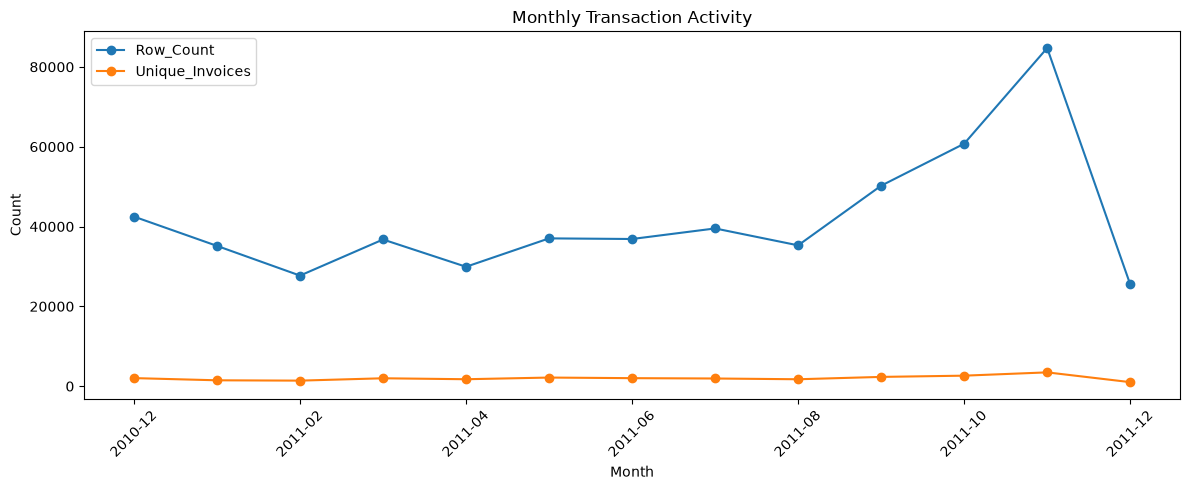

In [ ]:
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    format="%m/%d/%y %H:%M",
    errors="coerce"
)

print("Invalid dates:", df["InvoiceDate"].isna().sum())
print("Earliest date:", df["InvoiceDate"].min())
print("Latest date:", df["InvoiceDate"].max())

monthly_summary = (
    df.dropna(subset=["InvoiceDate"])
    .assign(
        Month=df["InvoiceDate"].dt.to_period("M").astype(str)
    )
    .groupby("Month")
    .agg(
        Row_Count=("InvoiceNo", "size"),
        Unique_Invoices=("InvoiceNo", "nunique"),
        Unique_Customers=("CustomerID", "nunique")
    )
)

print("\nMonthly Summary:")
print(monthly_summary)

monthly_summary[["Row_Count", "Unique_Invoices"]].plot(
    figsize=(12, 5),
    marker="o",
    title="Monthly Transaction Activity"
)

plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## سؤال ۷: چه تعداد رکورد و فاکتور با نشانه لغو ثبت شده‌اند؟

### پاسخ
در دیتاست:

- تعداد ردیف‌هایی که `InvoiceNo` آن‌ها با C شروع می‌شود: 9,288
- درصد این ردیف‌ها از کل دیتاست: حدود 1.71 درصد
- تعداد شماره فاکتورهای یکتای شروع‌شونده با C: 3,836

### چرا این سؤال را می‌پرسیم؟

برای شناسایی تراکنش‌هایی که ممکن است بیانگر لغو سفارش باشند و جلوگیری از تفسیر اشتباه آن‌ها به‌عنوان خرید عادی.

### تحلیل داده‌کاو

در این دیتاست، پیشوند C نشانه لغو فاکتور است. بااین‌حال، لغو فاکتور و مرجوعی کالا مفاهیم کاملاً یکسانی نیستند؛ بنابراین باید این اطلاعات را همراه با مقدار کالا و سایر مشخصات تراکنش بررسی کرد.

تعداد ردیف‌های لغوشده با تعداد فاکتورهای لغوشده یکسان نیست.

In [ ]:
cancelled_mask = (
    df["InvoiceNo"]
    .astype("string")
    .str.startswith("C", na=False)
)

print("Rows with cancellation prefix:", cancelled_mask.sum())

print(
    "Percentage of rows:",
    round(cancelled_mask.mean() * 100, 2),
    "%"
)

print(
    "Unique cancellation invoice numbers:",
    df.loc[cancelled_mask, "InvoiceNo"].nunique()
)

print("\nExamples:")
print(df.loc[cancelled_mask].head(10))

Rows with cancellation prefix: 9288
Percentage of rows: 1.71 %
Unique cancellation invoice numbers: 3836

Examples:
    InvoiceNo StockCode                        Description  Quantity  \
141   C536379         D                           Discount        -1   
154   C536383    35004C    SET OF 3 COLOURED  FLYING DUCKS        -1   
235   C536391     22556     PLASTERS IN TIN CIRCUS PARADE        -12   
236   C536391     21984   PACK OF 12 PINK PAISLEY TISSUES        -24   
237   C536391     21983   PACK OF 12 BLUE PAISLEY TISSUES        -24   
238   C536391     21980  PACK OF 12 RED RETROSPOT TISSUES        -24   
239   C536391     21484        CHICK GREY HOT WATER BOTTLE       -12   
240   C536391     22557   PLASTERS IN TIN VINTAGE PAISLEY        -12   
241   C536391     22553             PLASTERS IN TIN SKULLS       -24   
939   C536506     22960           JAM MAKING SET WITH JARS        -6   

            InvoiceDate  UnitPrice  CustomerID         Country  
141 2010-12-01 09:41:00   

## سؤال ۸: آیا در تعداد کالا و قیمت واحد، مقادیر منفی یا صفر وجود دارد؟

### پاسخ
در ستون `Quantity`:

- تعداد مقادیر منفی: 10,624
- تعداد مقادیر صفر: 0
- کمترین مقدار: 80,995-
- بیشترین مقدار: 80,995

در ستون `UnitPrice`:

- تعداد مقادیر منفی: 2
- تعداد مقادیر صفر: 2,515
- کمترین مقدار: 11,062.06-
- بیشترین مقدار: 38,970

### چرا این سؤال را می‌پرسیم؟

چون تعداد منفی ممکن است با مرجوعی کالا ارتباط داشته باشد و قیمت صفر یا منفی نیازمند بررسی از نظر معنای تجاری باشد. این مقادیر می‌توانند بر تحلیل فروش و رفتار خرید اثر بگذارند.

### تحلیل داده‌کاو

وجود Quantity منفی در کنار فاکتورهای لغوشده نشان می‌دهد که همه ردیف‌ها را نباید خرید عادی در نظر گرفت.

همچنین مقادیر بسیار بزرگ در Quantity و UnitPrice باید بررسی شوند؛ اما صرفاً بر اساس بزرگ یا منفی‌بودن، نمی‌توان آن‌ها را خطا اعلام کرد یا حذفشان کرد.

In [ ]:
for column in ["Quantity", "UnitPrice"]:
    print(f"\nColumn: {column}")
    print("Minimum:", df[column].min())
    print("Maximum:", df[column].max())
    print("Negative values:", (df[column] < 0).sum())
    print("Zero values:", (df[column] == 0).sum())
    print("Positive values:", (df[column] > 0).sum())

print("\nRows with negative Quantity:")
print(df[df["Quantity"] < 0].head(10))

print("\nRows with non-positive UnitPrice:")
print(df[df["UnitPrice"] <= 0].head(10))


Column: Quantity
Minimum: -80995
Maximum: 80995
Negative values: 10624
Zero values: 0
Positive values: 531285

Column: UnitPrice
Minimum: -11062.06
Maximum: 38970.0
Negative values: 2
Zero values: 2515
Positive values: 539392

Rows with negative Quantity:
    InvoiceNo StockCode                        Description  Quantity  \
141   C536379         D                           Discount        -1   
154   C536383    35004C    SET OF 3 COLOURED  FLYING DUCKS        -1   
235   C536391     22556     PLASTERS IN TIN CIRCUS PARADE        -12   
236   C536391     21984   PACK OF 12 PINK PAISLEY TISSUES        -24   
237   C536391     21983   PACK OF 12 BLUE PAISLEY TISSUES        -24   
238   C536391     21980  PACK OF 12 RED RETROSPOT TISSUES        -24   
239   C536391     21484        CHICK GREY HOT WATER BOTTLE       -12   
240   C536391     22557   PLASTERS IN TIN VINTAGE PAISLEY        -12   
241   C536391     22553             PLASTERS IN TIN SKULLS       -24   
939   C536506     22960

## سؤال ۹: توزیع Quantity و UnitPrice چگونه است و چه مقادیر افراطی‌ای دیده می‌شود؟

### پاسخ
بر اساس آمار توصیفی:

- میانه Quantity برابر 3 است.
- میانگین Quantity حدود 9.55 است.
- میانه UnitPrice برابر 2.08 پوند است.
- میانگین UnitPrice حدود 4.61 پوند است.

بیشترین Quantity برابر 80,995 و بیشترین UnitPrice برابر 38,970 است؛ این مقادیر فاصله زیادی با مقادیر معمول دارند.

### چرا این سؤال را می‌پرسیم؟

برای شناخت شکل توزیع متغیرهای عددی، تشخیص مقادیر افراطی احتمالی و بررسی اینکه آیا میانگین به‌تنهایی نماینده مناسبی برای رفتار داده‌هاست یا خیر.

### تحلیل داده‌کاو

فاصله میان میانگین و میانه در Quantity و UnitPrice نشان می‌دهد که توزیع این متغیرها متقارن نیست و مقادیر بزرگ می‌توانند میانگین را تحت تأثیر قرار دهند.

بااین‌حال، مقدار پرت آماری الزاماً به معنی خطای ثبت نیست. بررسی معنای تجاری هر مقدار باید پیش از تصمیم‌گیری درباره آن انجام شود.

            Quantity      UnitPrice
count  541909.000000  541909.000000
mean        9.552250       4.611114
std       218.081158      96.759853
min    -80995.000000  -11062.060000
25%         1.000000       1.250000
50%         3.000000       2.080000
75%        10.000000       4.130000
max     80995.000000   38970.000000

Selected percentiles:
       Quantity  UnitPrice
0.500      3.00     2.0800
0.750     10.00     4.1300
0.900     24.00     7.9500
0.950     29.00     9.9500
0.990    100.00    18.0000
0.999    468.92   205.5598


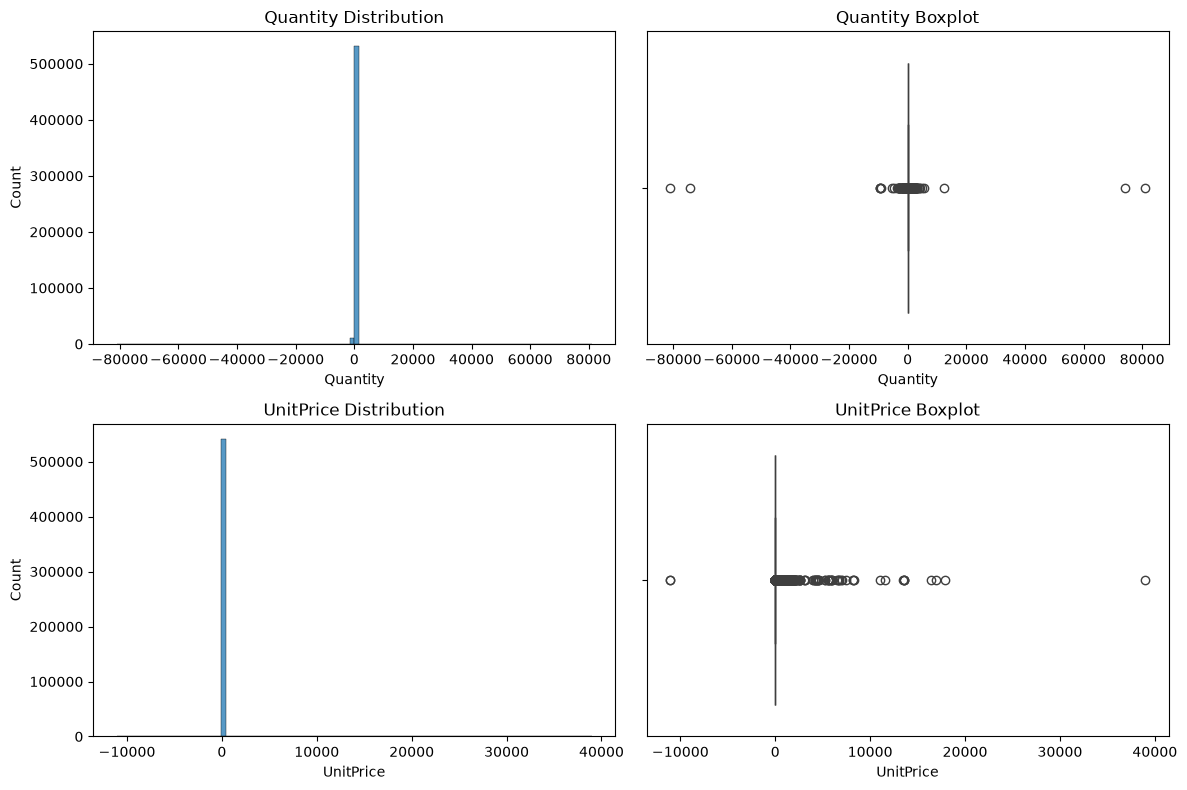

In [ ]:
print(df[["Quantity", "UnitPrice"]].describe())

print("\nSelected percentiles:")
print(
    df[["Quantity", "UnitPrice"]].quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
    )
)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df["Quantity"], bins=100, ax=axes[0, 0])
axes[0, 0].set_title("Quantity Distribution")

sns.boxplot(x=df["Quantity"], ax=axes[0, 1])
axes[0, 1].set_title("Quantity Boxplot")

sns.histplot(df["UnitPrice"], bins=100, ax=axes[1, 0])
axes[1, 0].set_title("UnitPrice Distribution")

sns.boxplot(x=df["UnitPrice"], ax=axes[1, 1])
axes[1, 1].set_title("UnitPrice Boxplot")

plt.tight_layout()
plt.show()

## سؤال ۱۰: کدام کشورها بیشترین سهم از رکوردها و مشتریان را دارند؟

### پاسخ
در دیتاست 38 کشور وجود دارد. بریتانیا بیشترین سهم را دارد:

- تعداد ردیف‌های بریتانیا: 495,478
- سهم از کل ردیف‌ها: حدود 91.43 درصد
- تعداد مشتریان یکتای دارای شناسه در بریتانیا: 3,950

### چرا این سؤال را می‌پرسیم؟

برای شناخت پراکندگی جغرافیایی داده و بررسی اینکه آیا دیتاست نماینده بازارهای مختلف است یا بیشتر بر یک بازار متمرکز شده است.

### تحلیل داده‌کاو

بخش عمده رکوردها مربوط به بریتانیاست؛ بنابراین نتایج کلی تحلیل بیشتر منعکس‌کننده رفتار خرید ثبت‌شده در این بازار خواهد بود.

همچنین تعداد ردیف‌های یک کشور را نباید با تعداد مشتریان آن کشور اشتباه گرفت. این تحلیل به‌تنهایی درباره سودآوری کشورها نتیجه‌گیری نمی‌کند.

Top countries by number of rows:
Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259
Name: count, dtype: int64

Top countries by unique customers:
Country
United Kingdom    3950
Germany             95
France              87
Spain               31
Belgium             25
Switzerland         21
Portugal            19
Italy               15
Finland             12
Austria             11
Name: CustomerID, dtype: int64

United Kingdom row percentage: 91.43 %


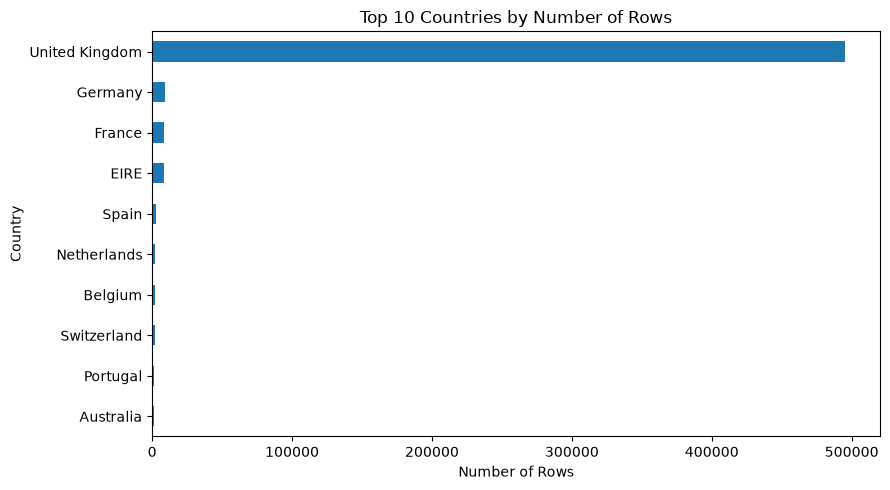

In [ ]:
country_rows = df["Country"].value_counts()

country_customers = (
    df.groupby("Country")["CustomerID"]
    .nunique()
    .sort_values(ascending=False)
)

print("Top countries by number of rows:")
print(country_rows.head(10))

print("\nTop countries by unique customers:")
print(country_customers.head(10))

print(
    "\nUnited Kingdom row percentage:",
    round(
        (df["Country"] == "United Kingdom").mean() * 100,
        2
    ),
    "%"
)

country_rows.head(10).sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Top 10 Countries by Number of Rows",
    xlabel="Number of Rows"
)

plt.tight_layout()
plt.show()

## سؤال ۱۱: پرتکرارترین محصولات از نظر تعداد ردیف‌های ثبت‌شده کدام‌اند؟

### پاسخ
تعداد کدهای محصول یکتا 4,070 است. پرتکرارترین کدها بر اساس تعداد ردیف‌های دیتاست عبارت‌اند از:

- `85123A`: تعداد 2,313 ردیف
- `22423`: تعداد 2,203 ردیف
- `85099B`: تعداد 2,159 ردیف
- `47566`: تعداد 1,727 ردیف
- `20725`: تعداد 1,639 ردیف

کد `85123A` مربوط به محصول WHITE HANGING HEART T-LIGHT HOLDER است.

### چرا این سؤال را می‌پرسیم؟

برای شناخت اولیه ترکیب محصولات و بررسی اینکه چه کالاهایی بیشتر در ردیف‌های تراکنش دیده می‌شوند.

### تحلیل داده‌کاو

تعداد دفعات ثبت یک محصول در ردیف‌ها، معیار فراوانی ثبت آن است؛ نه الزاماً تعداد واحدهای فروخته‌شده یا میزان درآمد حاصل از آن.

همچنین این سؤال برای پروژه ریزش مشتری جنبه توصیفی دارد و به‌تنهایی برای تشخیص مشتریان در آستانه ریزش کافی نیست.

           Row_Count                         Description
StockCode                                               
85123A          2313  WHITE HANGING HEART T-LIGHT HOLDER
22423           2203            REGENCY CAKESTAND 3 TIER
85099B          2159             JUMBO BAG RED RETROSPOT
47566           1727                       PARTY BUNTING
20725           1639             LUNCH BAG RED RETROSPOT
84879           1502       ASSORTED COLOUR BIRD ORNAMENT
22720           1477   SET OF 3 CAKE TINS PANTRY DESIGN 
22197           1476                SMALL POPCORN HOLDER
21212           1385     PACK OF 72 RETROSPOT CAKE CASES
20727           1350             LUNCH BAG  BLACK SKULL.


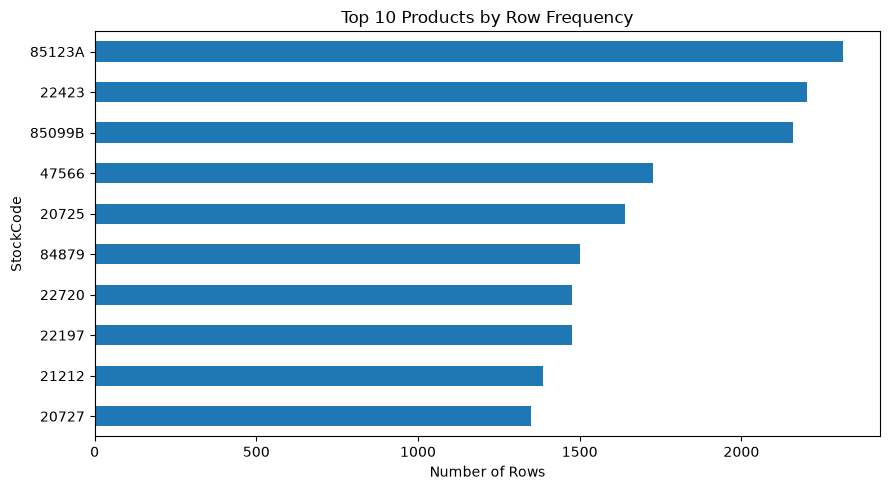

In [ ]:
top_products = df["StockCode"].value_counts().head(10)

product_names = (
    df.groupby("StockCode")["Description"]
    .first()
)

top_product_report = pd.DataFrame({
    "Row_Count": top_products,
    "Description": product_names.reindex(top_products.index)
})

print(top_product_report)

top_products.sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Top 10 Products by Row Frequency",
    xlabel="Number of Rows"
)

plt.tight_layout()
plt.show()

## سؤال ۱۲: هر فاکتور به‌طور معمول چند ردیف کالایی دارد؟

### پاسخ
در این دیتاست:

- تعداد فاکتورهای یکتا: 25,900
- میانگین تعداد ردیف برای هر فاکتور: حدود 20.92
- میانه تعداد ردیف برای هر فاکتور: 10
- بیشترین تعداد ردیف برای یک فاکتور: 1,114

### چرا این سؤال را می‌پرسیم؟

برای درک ساختار تراکنش‌ها و مشخص‌شدن اینکه چگونه چند ردیف کالایی به یک فاکتور تعلق دارند.

### تحلیل داده‌کاو

تفاوت میان میانگین و میانه و وجود فاکتورهایی با تعداد ردیف بسیار زیاد نشان می‌دهد که اندازه فاکتورها یکسان نیست.

این آمار مربوط به همه فاکتورهاست، از جمله موارد لغوشده؛ بنابراین تعداد ردیف‌های هر فاکتور را نباید بدون بررسی بیشتر معادل تعداد کالاهای خریداری‌شده در یک سفارش معتبر در نظر گرفت.

Unique invoices: 25900

Rows per invoice statistics:
count    25900.000000
mean        20.923127
std         43.031334
min          1.000000
25%          2.000000
50%         10.000000
75%         23.000000
max       1114.000000
dtype: float64

Median rows per invoice: 10.0
Maximum rows per invoice: 1114


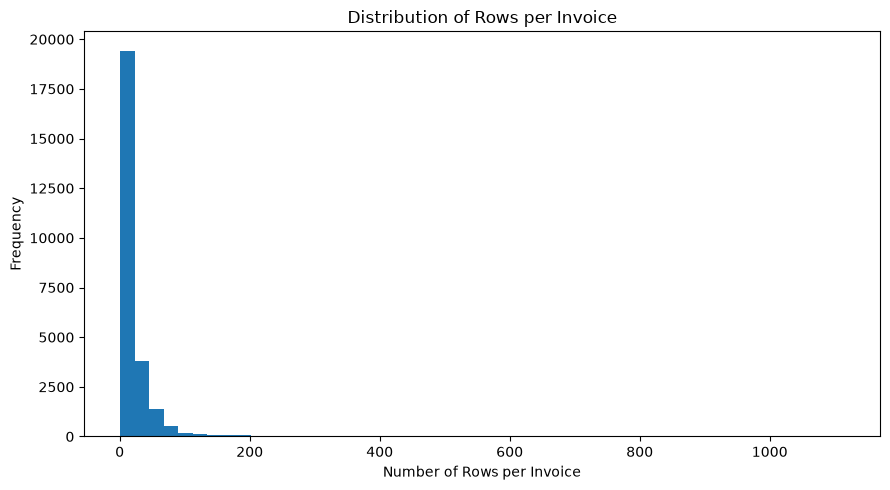

In [ ]:
invoice_row_counts = df.groupby("InvoiceNo").size()

print("Unique invoices:", invoice_row_counts.size)
print("\nRows per invoice statistics:")
print(invoice_row_counts.describe())

print(
    "\nMedian rows per invoice:",
    invoice_row_counts.median()
)

print(
    "Maximum rows per invoice:",
    invoice_row_counts.max()
)

invoice_row_counts.plot(
    kind="hist",
    bins=50,
    figsize=(9, 5),
    title="Distribution of Rows per Invoice",
    xlabel="Number of Rows per Invoice"
)

plt.tight_layout()
plt.show()

## سؤال ۱۳: مشتریان در چند فاکتور یکتا حضور دارند و توزیع تعداد فاکتورهای آن‌ها چگونه است؟

### پاسخ
برای مشتریان دارای شناسه:

- تعداد مشتریان یکتا: 4,372
- میانگین تعداد فاکتورهای یکتا به‌ازای هر مشتری: حدود 5.08
- میانه تعداد فاکتورها به‌ازای هر مشتری: 3
- بیشترین تعداد فاکتور برای یک مشتری: 248

### چرا این سؤال را می‌پرسیم؟

چون پروژه ما پیش‌بینی ریزش مشتری است و باید بدانیم فعالیت خرید بین مشتریان چگونه توزیع شده است. این تحلیل مشخص می‌کند که آیا تعداد فاکتورها بین مشتریان یکنواخت است یا تفاوت قابل‌توجهی دارد.

### تحلیل داده‌کاو

تفاوت میان میانگین و میانه و وجود مشتریانی با تعداد فاکتور زیاد نشان می‌دهد که سطح فعالیت خرید مشتریان یکسان نیست.

این اعداد بر اساس فاکتورهای یکتا و رکوردهای دارای شناسه محاسبه شده‌اند و شامل فاکتورهای لغوشده نیز می‌شوند. بنابراین هنوز معیار نهایی خرید معتبر یا برچسب ریزش نیستند.

Unique customers: 4372

Invoices per customer statistics:
count    4372.000000
mean        5.075480
std         9.338754
min         1.000000
25%         1.000000
50%         3.000000
75%         5.000000
max       248.000000
Name: InvoiceNo, dtype: float64

Median invoices per customer: 3.0
Maximum invoices per customer: 248


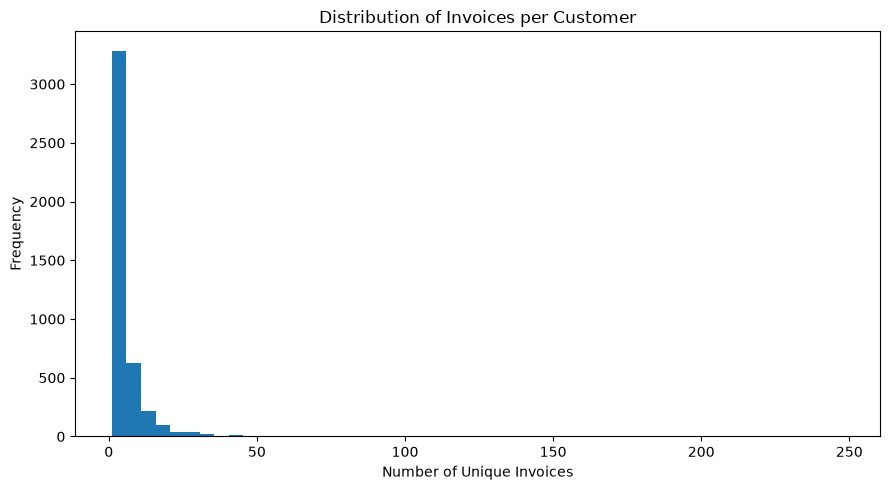

In [ ]:
customer_invoice_counts = (
    df.groupby("CustomerID")["InvoiceNo"]
    .nunique()
)

print("Unique customers:", customer_invoice_counts.size)

print("\nInvoices per customer statistics:")
print(customer_invoice_counts.describe())

print(
    "\nMedian invoices per customer:",
    customer_invoice_counts.median()
)

print(
    "Maximum invoices per customer:",
    customer_invoice_counts.max()
)

customer_invoice_counts.plot(
    kind="hist",
    bins=50,
    figsize=(9, 5),
    title="Distribution of Invoices per Customer",
    xlabel="Number of Unique Invoices"
)

plt.tight_layout()
plt.show()

## سؤال ۱۴: آیا دیتاست از قبل دارای برچسب Churn است؟

### پاسخ
خیر. دیتاست اصلی Online Retail ستون مستقیمی برای مشخص‌کردن ریزش مشتری ندارد.

اطلاعات موجود شامل شماره فاکتور، محصول، تعداد، تاریخ، قیمت، شناسه مشتری و کشور است.

### چرا این سؤال را می‌پرسیم؟

برای مشخص‌شدن اینکه آیا می‌توان مستقیماً مدل نظارت‌شده آموزش داد یا ابتدا باید متغیر هدف را تعریف و ایجاد کنیم.

### تحلیل داده‌کاو

برای پروژه شکار مشتریان در آستانه ریزش، باید تعریف عملیاتی ریزش مشخص شود.

برای مثال، می‌توان مشتری را در یک تاریخ مرجع ریزش‌کرده در نظر گرفت اگر در 90 روز بعد از آن تاریخ خرید معتبر نداشته باشد.

ساخت این برچسب مربوط به مرحله Data Preparation است؛ در Data Understanding فقط وجود یا نبود برچسب و امکان ساخت آن را بررسی می‌کنیم.

برای جلوگیری از نشت اطلاعات، ویژگی‌های مشتری باید فقط از اطلاعات موجود پیش از تاریخ مرجع ساخته شوند و اطلاعات آینده صرفاً برای تعیین برچسب به کار بروند.

In [ ]:
possible_target_names = [
    "Churn",
    "churn",
    "ChurnLabel",
    "churn_label",
    "IsChurn",
    "is_churn"
]

existing_targets = [
    column
    for column in possible_target_names
    if column in df.columns
]

if existing_targets:
    print("Possible target columns:", existing_targets)
else:
    print("No predefined churn target found.")
    print("The target must be defined in Data Preparation.")

No predefined churn target found.
The target must be defined in Data Preparation.


## سؤال ۱۵: آیا بازه زمانی موجود امکان تعریف برچسب ریزش با پنجره 90 روزه را فراهم می‌کند؟

### پاسخ
دیتاست از 1 دسامبر 2010 تا 9 دسامبر 2011 را پوشش می‌دهد.

اگر تعریف پروژه شامل 180 روز سابقه گذشته برای استخراج ویژگی‌ها و 90 روز آینده برای تعیین برچسب باشد، تاریخ مرجع باید در محدوده‌ای انتخاب شود که هر دو بازه در دیتاست موجود باشند.

با در نظر گرفتن مرزهای روزانه، بازه‌ای تقریبی از 30 مه تا 10 سپتامبر 2011 برای بررسی تاریخ‌های مرجع قابل‌بررسی است.

### چرا این سؤال را می‌پرسیم؟

چون برای برچسب‌گذاری ریزش باید هم اطلاعات گذشته مشتری و هم اطلاعات آینده او در دسترس باشد. اگر تاریخ مرجع بیش از حد به انتهای دیتاست نزدیک باشد، نمی‌توان وضعیت خرید مشتری را برای 90 روز کامل بعد از آن بررسی کرد.

### تحلیل داده‌کاو

بازه زمانی دیتاست محدود به حدود یک سال است. بنابراین امکان تعریف چند تاریخ مرجع وجود دارد، اما انتخاب تاریخ‌ها باید با دقت انجام شود.

تاریخ مرجع، طول پنجره سابقه و تعریف خرید معتبر باید در مرحله آماده‌سازی دقیق و ثابت شوند. این محدودیت زمانی همچنین بر نحوه ارزیابی مدل اثر می‌گذارد.

In [ ]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

first_date = df["InvoiceDate"].min().normalize()
last_date = df["InvoiceDate"].max().normalize()

history_days = 180
future_days = 90

earliest_reference_date = (
    first_date + pd.Timedelta(days=history_days)
)

latest_reference_date = (
    last_date - pd.Timedelta(days=future_days)
)

print("Dataset start:", first_date)
print("Dataset end:", last_date)

print("Earliest possible reference date:")
print(earliest_reference_date)

print("Latest possible reference date:")
print(latest_reference_date)

if earliest_reference_date <= latest_reference_date:
    print("A feasible reference-date window exists.")
else:
    print("The dataset period is insufficient for these windows.")

Dataset start: 2010-12-01 00:00:00
Dataset end: 2011-12-09 00:00:00
Earliest possible reference date:
2011-05-30 00:00:00
Latest possible reference date:
2011-09-10 00:00:00
A feasible reference-date window exists.


## سؤال ۱۶: چه محدودیت‌هایی ممکن است بر تحلیل و پیش‌بینی ریزش مشتری اثر بگذارند؟

### پاسخ
مهم‌ترین محدودیت‌های مشاهده‌شده عبارت‌اند از:

1. حدود 24.93 درصد ردیف‌ها فاقد CustomerID هستند.
2. تعداد 5,268 ردیف تکراری کامل وجود دارد.
3. برخی ردیف‌ها مربوط به لغو فاکتور هستند.
4. در Quantity مقادیر منفی و بسیار بزرگ مشاهده می‌شود.
5. در UnitPrice مقادیر صفر، منفی و بسیار بزرگ وجود دارد.
6. بازه زمانی داده‌ها تقریباً یک سال است و ماه دسامبر 2011 ناقص است.
7. حدود 91.43 درصد ردیف‌ها مربوط به بریتانیاست.
8. برچسب آماده‌ای برای ریزش مشتری وجود ندارد.
9. اطلاعات مستقیمی درباره علت ترک مشتری، هزینه کمپین بازگشت یا نتیجه تماس با مشتری در دیتاست ثبت نشده است.

### چرا این سؤال را می‌پرسیم؟

برای جمع‌بندی کیفیت، محدودیت‌ها و قابلیت استفاده از داده در پروژه و تعیین مسائلی که باید در مراحل بعدی مورد توجه قرار بگیرند.

### تحلیل داده‌کاو

دیتاست برای بررسی مقدماتی الگوی خرید و ساخت یک مسئله پیش‌بینی ریزش قابل استفاده است؛ اما پیش از مدل‌سازی باید تعریف ریزش، خرید معتبر و نحوه برخورد با تراکنش‌های لغوشده مشخص شود.

همچنین نمی‌توان صرفاً از این دیتاست نتیجه گرفت که یک کمپین بازگشت مشتری واقعاً مؤثر است؛ برای سنجش اثربخشی کمپین به اطلاعات مربوط به هزینه‌ها و نتایج اقدام‌های بازاریابی یا آزمایش کنترل‌شده نیاز داریم.

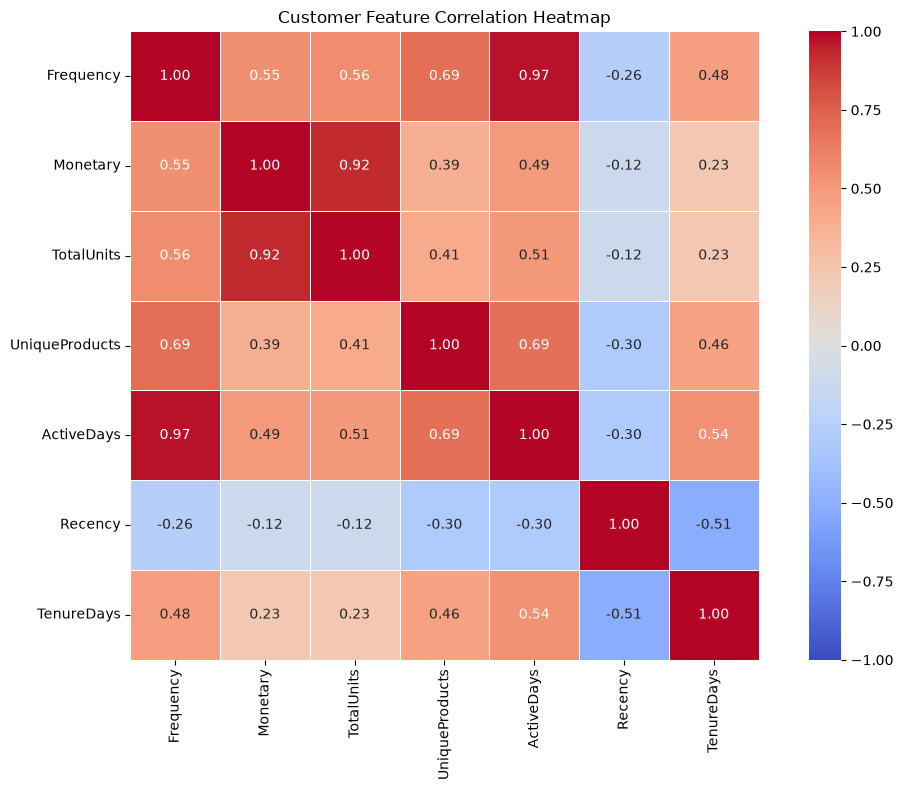

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df_corr = df.copy()

df_corr["InvoiceDate"] = pd.to_datetime(
    df_corr["InvoiceDate"],
    format="%m/%d/%y %H:%M",
    errors="coerce"
)

df_corr["Quantity"] = pd.to_numeric(
    df_corr["Quantity"], errors="coerce"
)
df_corr["UnitPrice"] = pd.to_numeric(
    df_corr["UnitPrice"], errors="coerce"
)

cancelled = df_corr["InvoiceNo"].astype("string").str.startswith(
    "C", na=False
)

valid = (
    (~cancelled)
    & (df_corr["Quantity"] > 0)
    & (df_corr["UnitPrice"] > 0)
    & df_corr["InvoiceDate"].notna()
    & df_corr["CustomerID"].notna()
)

sales = df_corr.loc[valid].copy()

# مبلغ هر ردیف خرید
sales["LineTotal"] = sales["Quantity"] * sales["UnitPrice"]

# ساخت ویژگی‌ها در سطح مشتری
customer_features = sales.groupby("CustomerID").agg(
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("LineTotal", "sum"),
    TotalUnits=("Quantity", "sum"),
    UniqueProducts=("StockCode", "nunique"),
    ActiveDays=("InvoiceDate", lambda x: x.dt.date.nunique()),
    FirstPurchase=("InvoiceDate", "min"),
    LastPurchase=("InvoiceDate", "max")
)

# تاریخ مرجع برای محاسبه فاصله از آخرین خرید
reference_date = sales["InvoiceDate"].max() + pd.Timedelta(days=1)

customer_features["Recency"] = (
    reference_date - customer_features["LastPurchase"]
).dt.days

customer_features["TenureDays"] = (
    customer_features["LastPurchase"]
    - customer_features["FirstPurchase"]
).dt.days

# انتخاب ویژگی‌های عددی معنادار؛ شناسه‌ها و تاریخ‌ها حذف می‌شوند
features = [
    "Frequency",
    "Monetary",
    "TotalUnits",
    "UniqueProducts",
    "ActiveDays",
    "Recency",
    "TenureDays"
]

corr = customer_features[features].corr(method="pearson")

# رسم هیت‌مپ
plt.figure(figsize=(11, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("Customer Feature Correlation Heatmap")
plt.tight_layout()
plt.show()
